# To be completed at the Data Science Workshop and in your own time.

These set of examples we will help you get familiar with non parametric tests and correlations within a Jupyter notebook.   The questions coloured green are important practice for CA, particularly CA 2.

Before attempting these examples, please ensure you have read through [Chapter 7 Jupyter Notebook](https://github.com/itrharrison/PX4146/blob/main/Chapter7/Chapter7.ipynb) and have completed the Learning Central **Chapter 7 quiz**.

***

# MCMC

## <font color=#30a64d>Question</font>

In Chapter 6, we saw that Professor Dumbledore, studying the extinction of dragons, discovers a new set of egg remnants in an unexplored valley in Madagascar. The remnants are radio carbon dated and found to have the following ages in years:

2141.22, 1781.15, 1523.37, 1816.90, 1932.29, 1541.21, 720.782, 1026.22, 1687.22, 2460.59

Professor Snape however did a previous study in the next valley where he found eggs that were on average 1200 years old, following a normal distribution with standard deviation of 300 years.

- Write an MCMC algorithm from scratch and use it to create a posterior distribution for the mean age of the eggs. What is the mean and variance for the posterior using your MCMC distribution?

- Check the MCMC has converged.

- How does this compare with the analytical values you derived in Chapter 6?

### Answer

*Your answer here*

The posterior mean is 1296.66
The posterior variance is 57810.29


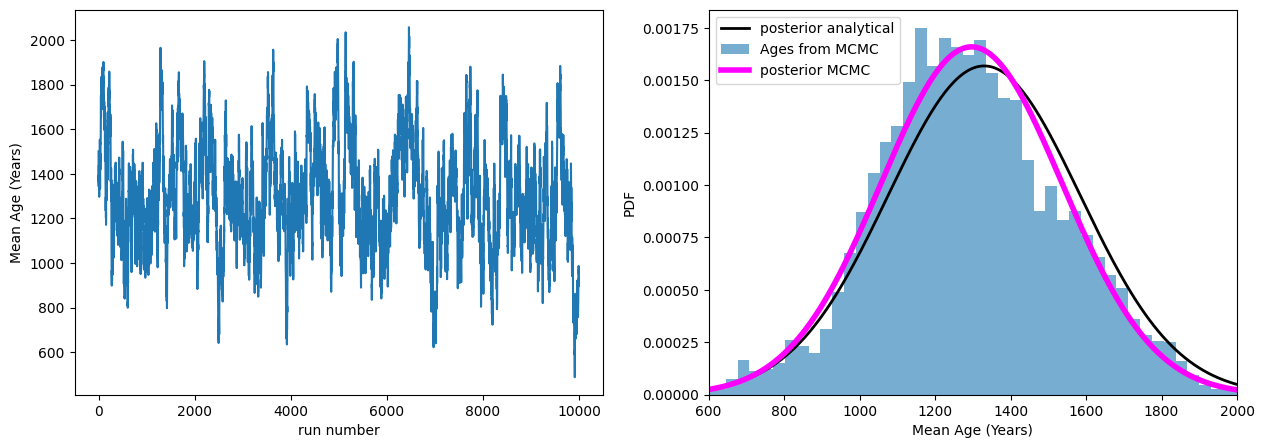

In [7]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

data = [2141.22, 1781.15, 1523.37, 1816.90, 1932.29, 1541.21, 720.782, 1026.22, 1687.22, 2460.59]
X_hat = np.mean(data)
sig_data = np.std(data)
snape_mean = 1200
snape_std = 300

def posterior(theta):
    val = norm.pdf(theta, X_hat, sig_data) * norm.pdf(theta, snape_mean, snape_std)
    return val

N_mcmc = 10000
theta_current = np.zeros(N_mcmc + 1)
theta_current[0] = 1500.
sigma_mcmc = 50.0

for i in range(N_mcmc):
    p_current = posterior(theta_current[i])
    dtheta = np.random.normal(0, sigma_mcmc)
    theta_proposed = theta_current[i] + dtheta
    p_proposed = posterior(theta_proposed)

    if p_proposed > p_current:
        theta_current[i+1] = theta_proposed
    else:
        p_new_move = p_proposed / p_current
        u_random = np.random.uniform(0, 1)
        if u_random <= p_new_move:
            theta_current[i+1] = theta_proposed
        else:
            theta_current[i+1] = theta_current[i]

mean_mcmc = np.mean(theta_current)
std_mcmc = np.std(theta_current)

print('The posterior mean is {:.2f}'.format(mean_mcmc))
print('The posterior variance is {:.2f}'.format(std_mcmc**2))

# tip : put the plotting routines outside the cell of the
# MCMC otherwise you'll need to do your N runs everytime you change a plotting feature
# generate x for plotting

plt.figure(figsize=(15,5))
plt.subplot(121)
plt.plot(theta_current)
plt.xlabel('run number')
plt.ylabel('Mean Age (Years)')

x = np.linspace(0, 3000, 500)
posterior_mcmc = norm.pdf(x, mean_mcmc, std_mcmc)

# Analytical calculations for comparison
precision_prior = 1.0 / (snape_std**2)
precision_data = 1.0 / (sig_data**2)
post_precision_analytic = precision_prior + precision_data
posterior_var_analytic = 1.0 / post_precision_analytic
posterior_mean_analytic = (snape_mean * precision_prior + X_hat * precision_data) / post_precision_analytic
posterior_std_analytic = np.sqrt(posterior_var_analytic)

plt.subplot(122)
#plots the analytic posterior
plt.plot(x, norm.pdf(x, posterior_mean_analytic, posterior_std_analytic), label='posterior analytical', c='black', lw=2)

# plots the mcmc generated posterior
plt.hist(theta_current[2000:], bins=50, density=True, label='Ages from MCMC', alpha=0.6)
plt.plot(x, posterior_mcmc, label='posterior MCMC', c='magenta', lw=4)
plt.legend(loc='upper left')
plt.xlim(600, 2000)
plt.xlabel('Mean Age (Years)')
plt.ylabel('PDF')
plt.show()

***